In [1]:
import matplotlib.pyplot as plt
import numpy as np
import h5py
from scipy.signal import hilbert

from pathlib import Path
from data_io.lussm_dataset import LUSSMDataset

In [2]:
folder = r'C:\Users\W\Desktop\MASTERRRRRRR\AA THESIS\data\LU_data\20261027\data'
dataset = LUSSMDataset(folder)

In [3]:
# %% create a b-scan from the time data
time_dataset = dataset.data['Time']
time_dataset = np.roll(time_dataset, -1, axis=0)  # [move dataset 100.mat to end]

# 1. Find the minimum sample length across all datasets to chop longer ones
nt = min([data.nt for data in time_dataset])
nf = min([data.nf for data in time_dataset])

# 2. Chop the reference time and frequency arrays to match the new minimum length
t_array = time_dataset[-1].t_array[:nt]
f_array = time_dataset[-1].f_array[:nf]

number_of_scans = len(time_dataset)

b_scan_time = np.zeros((number_of_scans, nt))
b_scan_fft = np.zeros((number_of_scans, nf), dtype='complex')

for n, data in enumerate(time_dataset):
    # 3. Truncate every individual a-scan and fft-scan to the exact minimum length
    b_scan_time[n, :] = data.time_data[:nt]
    b_scan_fft[n, :] = data.fft_data[:nf]

In [4]:
# %% filter frequency
b_scan_fft_filtered = np.zeros((number_of_scans, nf), dtype='complex')
b_scan_fft_removed = np.zeros((number_of_scans, nf), dtype='complex')
b_scan_time_filtered = np.zeros((number_of_scans, nf))
b_scan_time_removed = np.zeros((number_of_scans, nf))
b_scan_time_envelope = np.zeros((number_of_scans, nf))

# create the filter
f_low = 1.50e6
f_high = 12.0e6
order = 4
H_low = 1 / np.sqrt(1 + (f_low / np.maximum(np.abs(f_array), 1e-30)) ** (4 * order))
H_high = 1 / np.sqrt(1 + (np.abs(f_array) / f_high) ** (4 * order))
H = H_low * H_high

for dataset_number in range(number_of_scans):

    # filter the data
    spectrum = b_scan_fft[dataset_number, :]
    spectrum_filtered = spectrum * H
    a_scan_filtered = np.fft.ifft(np.fft.ifftshift(spectrum_filtered), n=nf)

    spectrum_removed = spectrum - spectrum_filtered
    a_scan_removed = np.fft.ifft(np.fft.ifftshift(spectrum_removed), n=nf)

    # compute the analytic signal
    analytic_a_scan = hilbert(np.real(a_scan_filtered))
    a_scan_envelope = np.abs(analytic_a_scan)
    a_scan_phase = np.unwrap(np.angle(analytic_a_scan))

    # save the data
    b_scan_fft_filtered[dataset_number, :] = spectrum_filtered
    b_scan_fft_removed[dataset_number, :] = spectrum_removed
    b_scan_time_filtered[dataset_number, :] = a_scan_filtered
    b_scan_time_removed[dataset_number, :] = a_scan_removed
    b_scan_time_envelope[dataset_number, :] = a_scan_envelope


C:\Users\W\AppData\Local\Temp\ipykernel_8232\1688014467.py:12: RuntimeWarning: overflow encountered in power
  H_low = 1 / np.sqrt(1 + (f_low / np.maximum(np.abs(f_array), 1e-30)) ** (4 * order))
C:\Users\W\AppData\Local\Temp\ipykernel_8232\1688014467.py:34: ComplexWarning: Casting complex values to real discards the imaginary part
  b_scan_time_filtered[dataset_number, :] = a_scan_filtered
C:\Users\W\AppData\Local\Temp\ipykernel_8232\1688014467.py:35: ComplexWarning: Casting complex values to real discards the imaginary part
  b_scan_time_removed[dataset_number, :] = a_scan_removed


Text(0.5, 0.98, 'meas_03_time')

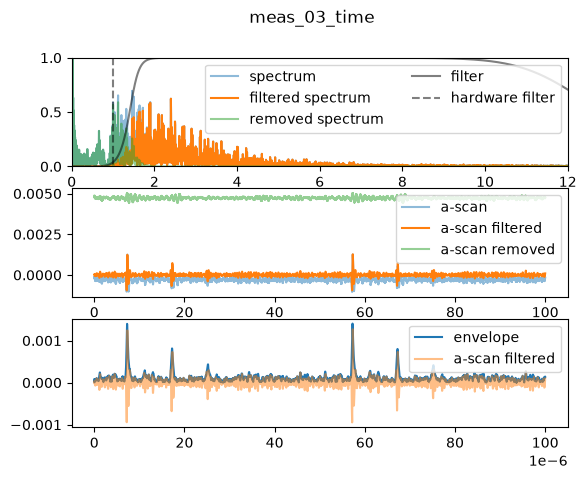

In [5]:
# %% plot data
plt.figure(1)
plt.clf()

dataset_number = 1

plt.subplot(311)

plt.plot(f_array,
         np.abs(b_scan_fft[dataset_number, :]),
         color='C0',
         alpha=0.5,
         label='spectrum')

plt.plot(f_array,
         np.abs(b_scan_fft_filtered[dataset_number, :]),
         color='C1',
         label='filtered spectrum')

plt.plot(f_array,
         np.abs(b_scan_fft_removed[dataset_number, :]),
         color='C2',
         alpha=0.5,
         label='removed spectrum')

plt.plot(f_array,
         H,
         color='k',
         alpha=0.5,
         label='filter')

plt.vlines(1e6, -1, 1,
           color='k',
           ls='--',
           alpha=0.5,
           label='hardware filter')


plt.xlim(0.0, 12e6)
plt.ylim(0.0, 1)
plt.gca().ticklabel_format(axis='x', style='sci', scilimits=(6, 6))
plt.legend(loc='upper right',
           ncols=2)

plt.subplot(312)

plt.plot(t_array,
         b_scan_time[dataset_number, :],
         color='C0',
         alpha=0.5,
         label='a-scan')

plt.plot(t_array,
         b_scan_time_filtered[dataset_number, :nt],
         color='C1',
         label='a-scan filtered')

plt.plot(t_array,
         b_scan_time_removed[dataset_number, :nt] + 0.005,
         color='C2',
         alpha=0.5,
         label='a-scan removed')

plt.gca().ticklabel_format(axis='x', style='sci', scilimits=(-6, -6))
plt.legend(loc='upper right')

plt.subplot(313)

plt.plot(t_array,
         b_scan_time_envelope[dataset_number, :nt],
         color='C0',
         label='envelope')
plt.plot(t_array,
         b_scan_time_filtered[dataset_number, :nt],
         color='C1',
         alpha=0.5,
         label='a-scan filtered')

plt.gca().ticklabel_format(axis='x', style='sci', scilimits=(-6, -6))
plt.legend(loc='upper right')

plt.suptitle(time_dataset[dataset_number].filename)


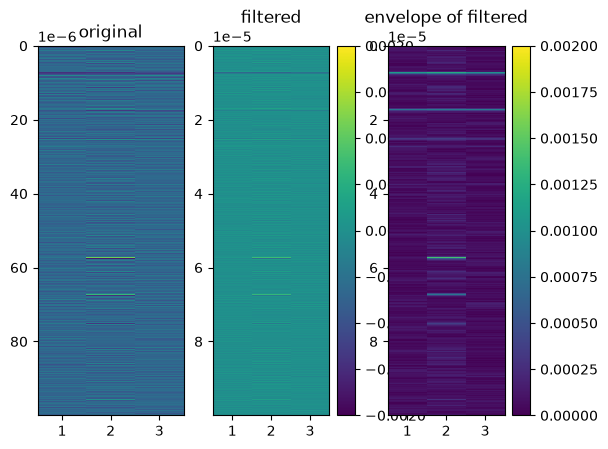

In [6]:
plt.figure(2)
plt.clf()

plt.subplot(131)

x_values = np.array([1, 2, 3])
dx = np.min(np.diff(x_values))
x_regular = np.arange(x_values.min(), x_values.max() + dx, dx)
idx = np.round((x_values - x_values.min()) / dx).astype(int)

b_scan_time_T = b_scan_time[:, :nt].T
b_scan_time_2 = np.full((b_scan_time_T.shape[0], len(x_regular)), np.nan)
b_scan_time_2[:, idx] = b_scan_time_T

b_scan_time_filtered_T = b_scan_time_filtered[:, :nt].T
b_scan_time_filtered_2 = np.full((b_scan_time_filtered_T.shape[0], len(x_regular)), np.nan)
b_scan_time_filtered_2[:, idx] = b_scan_time_filtered_T

b_scan_time_envelope_T = b_scan_time_envelope[:, :nt].T
b_scan_time_envelope_2 = np.full((b_scan_time_envelope_T.shape[0], len(x_regular)), np.nan)
b_scan_time_envelope_2[:, idx] = b_scan_time_envelope_T

plt.imshow(
    b_scan_time_2,
    extent=(x_regular.min() - dx/2, x_regular.max() + dx/2, t_array[-1], t_array[0]),
    cmap='viridis',
    aspect='auto',
    interpolation='nearest',
)
plt.title('original')

plt.xticks((1, 2, 3))
plt.gca().ticklabel_format(axis='y', style='sci', scilimits=(-6, -6))

plt.subplot(132)

plt.imshow(
    b_scan_time_filtered_2,
    extent=(0.5, number_of_scans+0.5, t_array[-1], t_array[0]),
    cmap='viridis',
    aspect='auto',
    interpolation='nearest',
    vmin=-0.002,
    vmax=0.002
)
plt.colorbar()
plt.title('filtered')

plt.subplot(133)

plt.imshow(
    b_scan_time_envelope_2,
    extent=(0.5, number_of_scans+0.5, t_array[-1], t_array[0]),
    cmap='viridis',
    aspect='auto',
    interpolation='nearest',
    vmin=0.0,
    vmax=0.002
)
plt.colorbar()

plt.title('envelope of filtered')

plt.show()